<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6c_quaternions_edo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI (c): EDOs com quaternions

## Integrar a orientação, a porca que capota no espaço, e o erro de cone das centrais inerciais

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 6](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb)) · **Anterior:** [X6b_quaternions_sistemas.ipynb](X6b_quaternions_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6b_quaternions_sistemas.ipynb)) · **Próximo:** [X6d_quaternions_perseguicao.ipynb](X6d_quaternions_perseguicao.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6d_quaternions_perseguicao.ipynb))

**Objetivo.** Um giroscópio mede a velocidade angular $\boldsymbol\omega$ **no corpo**. A orientação obedece a

$$\dot q=\tfrac12\,q\otimes(0,\boldsymbol\omega),$$

uma EDO linear em $q$, mas com coeficientes que não comutam entre instantes diferentes: $\boldsymbol\omega(t_1)$ e $\boldsymbol\omega(t_2)$ apontam em direções diferentes, e girar em torno de uma e depois da outra não é o mesmo que o contrário (notebook VI(a), o livro). No domínio V, a parte que não comutava era a translação; aqui é a própria rotação, e o **colchete de Lie** de $\mathfrak{so}(3)$ é o produto vetorial: $[\boldsymbol\omega_1,\boldsymbol\omega_2]=\boldsymbol\omega_1\times\boldsymbol\omega_2$.

**Roteiro**
1. Integradores: Euler, RK4 nas componentes, Magnus de ordens 2 e 4, com e sem o colchete
2. O efeito Dzhanibekov: a porca que capota no espaço, e as leis de conservação que o integrador tem de respeitar
3. O erro de cone (*coning*): o colchete de Lie como algoritmo de engenharia
4. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

rng = np.random.default_rng(63)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

---

## 1. Integradores

Uma velocidade angular que varia no tempo em direção e intensidade, $\boldsymbol\omega(t)=(\mathrm{sen}\,t,\ \cos2t,\ 0{,}5+0{,}3\,\mathrm{sen}\,3t)$ rad/s, integrada de $t=0$ a $4$ s. Os métodos:
- **Euler** e **RK4 nas componentes**: tratam $q$ como um vetor de $\mathbb R^4$ e não sabem que ele deveria ficar na esfera unitária;
- **Magnus de ordem 2**: $q\leftarrow q\,\mathrm{Exp}\big(h\,\boldsymbol\omega(t+h/2)\big)$, o "passo exponencial" com a velocidade do meio;
- **Magnus de ordem 4**: com os dois pontos de Gauss–Legendre $\boldsymbol\omega_1,\boldsymbol\omega_2$ (em $t+(\tfrac12\mp\tfrac{\sqrt3}6)h$),
$$\boldsymbol\Omega=\tfrac h2(\boldsymbol\omega_1+\boldsymbol\omega_2)+\tfrac{\sqrt3}{12}h^2\,\boldsymbol\omega_1\times\boldsymbol\omega_2,\qquad q\leftarrow q\,\mathrm{Exp}(\boldsymbol\Omega);$$
- **Magnus de ordem 4 sem o colchete**: o mesmo, sem o termo $\boldsymbol\omega_1\times\boldsymbol\omega_2$.

Os três últimos ficam na esfera por construção (são produtos de quaternions unitários). A referência é o Magnus de ordem 4 com passo $10^{-4}$, conferido contra o RK4 com passo $10^{-3}$.

In [2]:
w_t = lambda t: np.array([np.sin(t), np.cos(2 * t), 0.5 + 0.3 * np.sin(3 * t)])
f = lambda t, q: 0.5 * qmul(q, np.concatenate([[0.0], w_t(t)]))
CG = np.sqrt(3) / 6

def integra(metodo, h, T=4.0):
    q = np.array([1.0, 0, 0, 0]); n = int(round(T / h))
    for k_ in range(n):
        t = k_ * h
        if metodo == "Euler":
            q = q + h * f(t, q)
        elif metodo == "RK4 nas componentes":
            k1 = f(t, q); k2 = f(t + h / 2, q + h / 2 * k1); k3 = f(t + h / 2, q + h / 2 * k2); k4 = f(t + h, q + h * k3)
            q = q + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        elif metodo == "Magnus 2":
            q = qmul(q, qexp(h * w_t(t + h / 2)))
        else:
            w1, w2 = w_t(t + (0.5 - CG) * h), w_t(t + (0.5 + CG) * h)
            Om = h / 2 * (w1 + w2)
            if metodo == "Magnus 4": Om = Om + np.sqrt(3) / 12 * h**2 * np.cross(w1, w2)
            q = qmul(q, qexp(Om))
    return q

ref = integra("Magnus 4", 1e-4)
confere("a referência concorda com o RK4 de passo pequeno", qnorm(integra("RK4 nas componentes", 1e-3)), ref, tol=1e-11)
dist = lambda q: np.linalg.norm(qlog(qmul(qconj(ref), qnorm(q))))
hs = [0.1, 0.05, 0.025, 0.0125]
metodos = ["Euler", "RK4 nas componentes", "Magnus 2", "Magnus 4 sem colchete", "Magnus 4"]
print(f"{'método':24s}" + "".join(f"   h = {h:<8}" for h in hs) + "   ordem    | |q| − 1 | (h = 0,1)")
ordens = {}
for m in metodos:
    qs = [integra(m, h) for h in hs]
    e = np.array([dist(q) for q in qs])
    ordens[m] = np.polyfit(np.log(hs), np.log(e), 1)[0]
    print(f"{m:24s}" + "".join(f"   {x:10.2e}  " for x in e) + f"   {ordens[m]:5.2f}    {abs(np.linalg.norm(qs[0]) - 1):.1e}")
confere("ordens observadas: 1, 4, 2, 2 e 4", [ordens[m] for m in metodos], [1, 4, 2, 2, 4], tol=0.05)

OK   a referência concorda com o RK4 de passo pequeno:  diferença máxima = 1.44e-14
método                     h = 0.1        h = 0.05       h = 0.025      h = 0.0125     ordem    | |q| − 1 | (h = 0,1)
Euler                        9.42e-02       4.68e-02       2.33e-02       1.17e-02      1.01    6.4e-02
RK4 nas componentes          1.48e-06       9.30e-08       5.82e-09       3.64e-10      4.00    1.0e-07
Magnus 2                     2.11e-03       5.28e-04       1.32e-04       3.30e-05      2.00    3.3e-16
Magnus 4 sem colchete        2.96e-03       7.41e-04       1.85e-04       4.64e-05      2.00    0.0e+00
Magnus 4                     3.85e-06       2.41e-07       1.50e-08       9.41e-10      4.00    8.9e-16
OK   ordens observadas: 1, 4, 2, 2 e 4:  diferença máxima = 5.15e-03


**Leitura.** As ordens saem como a teoria diz: 1 para Euler, 2 para Magnus 2, 4 para o RK4 nas componentes e para o Magnus 4. Sem o colchete, o Magnus "de ordem 4" cai para ordem 2, e fica até um pouco pior que o Magnus 2: os dois pontos de Gauss sozinhos não compensam a não comutatividade. O RK4 nas componentes é preciso, mas sai da esfera ($|q|-1=10^{-7}$ com $h=0{,}1$); o Euler sai muito ($6\%$). Os métodos de Magnus ficam na esfera até o arredondamento, por construção. É a mesma tabela do notebook V(c), agora com o colchete sendo um produto vetorial.

---

## 2. O efeito Dzhanibekov

Em 1985, a bordo da estação Salyut 7, o cosmonauta Vladimir Dzhanibekov desenroscou uma porca de borboleta, que saiu girando no ar, e viu algo estranho: a cada tantos segundos, a porca **capotava** meia volta, sem nada que a empurrasse, e depois capotava de volta. O mesmo acontece com uma raquete de tênis jogada para cima girando em torno do eixo "do meio": é o **teorema da raquete de tênis**. Um corpo rígido livre gira de forma estável em torno do eixo de maior e de menor momento de inércia, e de forma instável em torno do intermediário.

As equações de Euler para o corpo livre, com o tensor de inércia diagonal $I=\mathrm{diag}(I_1,I_2,I_3)$ nos eixos do corpo, são

$$I\,\dot{\boldsymbol\omega}=(I\boldsymbol\omega)\times\boldsymbol\omega,\qquad \dot q=\tfrac12\,q\otimes(0,\boldsymbol\omega).$$

Duas quantidades se conservam e servem de conferência: a energia $E=\tfrac12\boldsymbol\omega^\top I\boldsymbol\omega$ e o **vetor** momento angular **no mundo**, $\mathbf L=R(q)\,I\boldsymbol\omega$. A segunda é exigente: ela só se conserva se $q$ e $\boldsymbol\omega$ forem integrados corretamente **juntos**. Linearizando em torno de uma rotação pura no eixo 2, uma perturbação pequena cresce como $e^{\lambda t}$ com

$$\lambda=\omega_0\sqrt{\frac{(I_2-I_1)(I_3-I_2)}{I_1I_3}}.$$

A porca: $I=\mathrm{diag}(1,2,3)$, girando a 2 rad/s em torno do eixo 2, com uma perturbação de 0,01 rad/s nos outros dois.

In [3]:
I = np.array([1.0, 2.0, 3.0])
dw = lambda w: np.cross(I * w, w) / I

def campo(s):
    q, w = s[:4], s[4:]
    return np.concatenate([0.5 * qmul(q, np.concatenate([[0.0], w])), dw(w)])

def rk4(s, h):
    k1 = campo(s); k2 = campo(s + h / 2 * k1); k3 = campo(s + h / 2 * k2); k4 = campo(s + h * k3)
    return s + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def gira(w0, T=40.0, h=0.005):
    s = np.concatenate([[1.0, 0, 0, 0], w0]); hist = [s]
    for _ in range(int(round(T / h))):
        s = rk4(s, h); hist.append(s)
    return np.arange(len(hist)) * h, np.array(hist)

ts, H = gira(np.array([0.01, 2.0, 0.01]))
E = 0.5 * np.sum(I * H[:, 4:]**2, axis=1)
L = np.array([qmat(qnorm(s[:4])) @ (I * s[4:]) for s in H])
confere("energia conservada (40 s, 8000 passos de RK4)", E, E[0] * np.ones_like(E), tol=1e-9, relativo=True)
confere("momento angular no mundo conservado (as três componentes)", L, np.tile(L[0], (len(L), 1)), tol=1e-8, relativo=True)
print(f"| |q| − 1 | no fim: {abs(np.linalg.norm(H[-1, :4]) - 1):.1e}  (RK4 nas componentes, sem renormalizar)")

# o eixo 2 do corpo, projetado na direção de L: +1 no começo; −1 quando a porca capotou
eixo2 = np.array([qrot(qnorm(s[:4]), [0, 1, 0]) for s in H]) @ (L[0] / np.linalg.norm(L[0]))
virada = ts[1:][np.diff(np.sign(eixo2)) != 0]
print("a porca capota (o eixo 2 cruza o plano perpendicular a L) em t =", np.round(virada, 2), "s")

# a taxa de crescimento no começo, contra a linearização
lam = 2.0 * np.sqrt((I[1] - I[0]) * (I[2] - I[1]) / (I[0] * I[2]))
jan = (ts > 0.5) & (ts < 2.5)
lam_obs = np.polyfit(ts[jan], np.log(np.hypot(H[jan, 4], H[jan, 6])), 1)[0]
print(f"crescimento da perturbação: observado λ = {lam_obs:.4f} /s, linearização λ = {lam:.4f} /s")
confere("a perturbação cresce com a taxa da linearização (a menos de 8%)", lam_obs, lam, tol=0.08, relativo=True)

for eixo in [0, 2]:
    w0 = np.array([0.01, 0.01, 0.01]); w0[eixo] = 2.0
    _, H2 = gira(w0, T=40.0)
    desvio = max(np.degrees(np.arccos(np.clip(abs(qrot(qnorm(s[:4]), np.eye(3)[eixo]) @ qrot(qnorm(H2[0, :4]), np.eye(3)[eixo])), -1, 1))) for s in H2[::50])
    print(f"girando em torno do eixo {eixo + 1}: o eixo se afasta no máximo {desvio:.2f}° da direção inicial em 40 s")
    confere(f"  o eixo {eixo + 1} é estável (desvio < 5°)", desvio < 5, True)

OK   energia conservada (40 s, 8000 passos de RK4):  diferença relativa máxima = 6.64e-12
OK   momento angular no mundo conservado (as três componentes):  diferença relativa máxima = 1.31e-10
| |q| − 1 | no fim: 4.8e-12  (RK4 nas componentes, sem renormalizar)


a porca capota (o eixo 2 cruza o plano perpendicular a L) em t = [ 6.06 17.04 28.02 38.99] s
crescimento da perturbação: observado λ = 1.2090 /s, linearização λ = 1.1547 /s
OK   a perturbação cresce com a taxa da linearização (a menos de 8%):  diferença relativa máxima = 4.70e-02


girando em torno do eixo 1: o eixo se afasta no máximo 2.18° da direção inicial em 40 s
OK     o eixo 1 é estável (desvio < 5°):  diferença máxima = 0.00e+00


girando em torno do eixo 3: o eixo se afasta no máximo 0.41° da direção inicial em 40 s
OK     o eixo 3 é estável (desvio < 5°):  diferença máxima = 0.00e+00


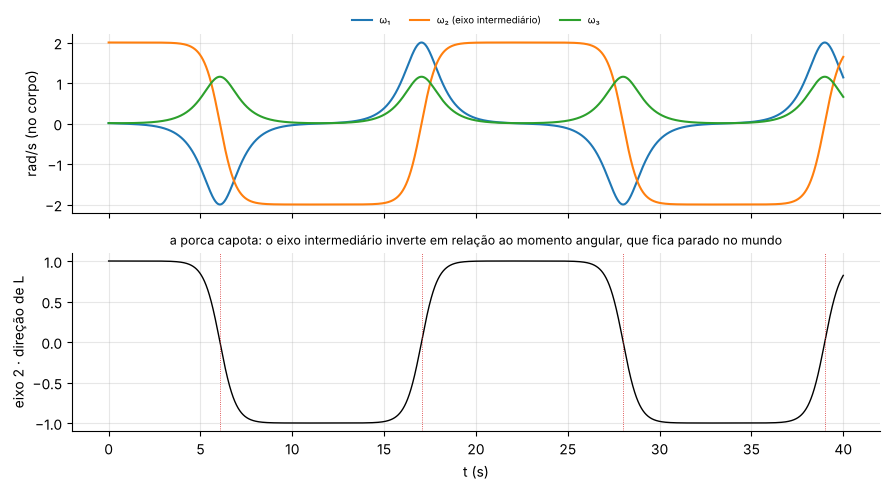

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axs[0].plot(ts, H[:, 4], label="ω₁"); axs[0].plot(ts, H[:, 5], label="ω₂ (eixo intermediário)"); axs[0].plot(ts, H[:, 6], label="ω₃")
axs[0].set_ylabel("rad/s (no corpo)"); axs[0].legend(fontsize=7, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
axs[1].plot(ts, eixo2, "k-", lw=1)
for v in virada: axs[1].axvline(v, color="C3", lw=0.6, ls=":")
axs[1].set_ylabel("eixo 2 · direção de L"); axs[1].set_xlabel("t (s)")
axs[1].set_title("a porca capota: o eixo intermediário inverte em relação ao momento angular, que fica parado no mundo", fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** A porca girando em torno do eixo intermediário capota a cada 11 s (a primeira capotada, mais cedo, depende do tamanho da perturbação inicial), e volta. Em torno dos eixos 1 e 3, ela só oscila um pouco: os dois são estáveis, como diz o teorema. A perturbação cresce com taxa 1,21 /s, 5% acima da linearização (1,15 /s): a perturbação de 0,01 rad/s não é infinitesimal, e há um transitório no começo.

O mais importante são as conservações. A energia e as **três componentes** do momento angular no mundo ficam constantes a menos de $10^{-10}$ ao longo de 40 s, inclusive durante as capotadas, em que $\boldsymbol\omega$ no corpo muda completamente. O vetor $\mathbf L$ é fixo no espaço; quem gira é o corpo em volta dele. Como $\mathbf L=R(q)\,I\boldsymbol\omega$ mistura a orientação com a velocidade, essa conferência pegaria qualquer erro de convenção entre os dois (um $q\,\omega$ no lugar de $\omega\,q$, por exemplo).

---

## 3. O erro de cone das centrais inerciais

Uma central inercial *strapdown* (a de um avião, de um míssil, de um celular) não guarda $\boldsymbol\omega(t)$: o giroscópio entrega, a cada intervalo $h$, o **incremento angular** $\Delta\boldsymbol\theta_k=\int_{t_k}^{t_k+h}\boldsymbol\omega\,dt$. O jeito óbvio de atualizar a atitude é $q\leftarrow q\,\mathrm{Exp}(\Delta\boldsymbol\theta_k)$. Ele erra quando $\boldsymbol\omega$ muda de direção dentro do intervalo, e o caso mais traiçoeiro é o **movimento de cone**: dois eixos oscilando com a mesma frequência, defasados de 90°, de modo que um eixo do corpo descreve um cone. Num avião, é o efeito de uma vibração. A atitude oscila, mas o corpo também gira lentamente em torno do eixo do cone, e o algoritmo ingênuo erra esse giro sistematicamente, todo intervalo no mesmo sentido: uma **deriva** que cresce sem parar, mesmo com giroscópios perfeitos.

A correção clássica (Miller, 1983) divide o intervalo em duas metades, com incrementos $\Delta\boldsymbol\theta_1$ e $\Delta\boldsymbol\theta_2$, e usa

$$\boldsymbol\phi=\Delta\boldsymbol\theta_1+\Delta\boldsymbol\theta_2+\tfrac23\,\Delta\boldsymbol\theta_1\times\Delta\boldsymbol\theta_2,\qquad q\leftarrow q\,\mathrm{Exp}(\boldsymbol\phi).$$

O termo extra é um colchete de Lie: o mesmo que o Magnus de ordem 4 da seção 1, escrito com incrementos em vez de velocidades.

O movimento: $q(t)=\big(\cos\frac a2,\ \mathrm{sen}\frac a2\cos\Omega t,\ \mathrm{sen}\frac a2\,\mathrm{sen}\,\Omega t,\ 0\big)$, um cone de meia-abertura $a=1°$ a 20 Hz. A atitude exata é conhecida em todo instante, e os incrementos do giroscópio são calculados com quadratura de Gauss de 8 pontos (exatos até o arredondamento).

In [5]:
a_c, Om = np.radians(1.0), 2 * np.pi * 20
q_cone = lambda t: np.array([np.cos(a_c / 2), np.sin(a_c / 2) * np.cos(Om * t), np.sin(a_c / 2) * np.sin(Om * t), 0.0])
dq_cone = lambda t: np.array([0.0, -np.sin(a_c / 2) * Om * np.sin(Om * t), np.sin(a_c / 2) * Om * np.cos(Om * t), 0.0])
w_cone = lambda t: 2 * qmul(qconj(q_cone(t)), dq_cone(t))[1:]           # ω no corpo, de q̇ = ½ q ω
confere("a velocidade angular em z é constante, −Ω(1 − cos a)", [w_cone(t)[2] for t in rng.random(5)], [-Om * (1 - np.cos(a_c))] * 5, tol=1e-12)
print(f"o corpo gira em z a {np.degrees(-w_cone(0)[2]):.3f} °/s, enquanto x e y oscilam com amplitude {np.degrees(np.linalg.norm(w_cone(0)[:2])):.1f} °/s")

xg, wg = np.polynomial.legendre.leggauss(8)
def incremento(t0, t1):
    m, r_ = (t0 + t1) / 2, (t1 - t0) / 2
    return r_ * sum(wi * w_cone(m + r_ * xi) for xi, wi in zip(xg, wg))

T = 1.0
print("erro de atitude depois de 1 s, em segundos de arco (= deriva em graus por hora)")
print("frequência do giroscópio    ingênuo      com a correção de cone")
res = []
for hz in [100, 200, 400, 800]:
    h = 1 / hz; n = int(round(T * hz))
    q1 = q2 = q_cone(0)
    for k_ in range(n):
        t = k_ * h
        q1 = qmul(q1, qexp(incremento(t, t + h)))
        d1, d2 = incremento(t, t + h / 2), incremento(t + h / 2, t + h)
        q2 = qmul(q2, qexp(d1 + d2 + 2 / 3 * np.cross(d1, d2)))
    e1, e2 = [np.linalg.norm(qlog(qmul(qconj(q_cone(T)), q_))) for q_ in (q1, q2)]
    res.append((h, e1, e2))
    print(f"{hz:10d} Hz            {np.degrees(e1) * 3600:12.1f}           {np.degrees(e2) * 3600:12.4f}")
res = np.array(res)
o1 = np.polyfit(np.log(res[:, 0]), np.log(res[:, 1]), 1)[0]; o2 = np.polyfit(np.log(res[:, 0]), np.log(res[:, 2]), 1)[0]
print(f"ordem da deriva em h: ingênuo {o1:.2f}, corrigido {o2:.2f}")
confere("a deriva do algoritmo ingênuo cai com h²", o1, 2, tol=0.05)
confere("com a correção de cone, com h⁴", o2, 4, tol=0.05)
confere("a 100 Hz, a correção reduz a deriva mais de 40 vezes", res[0, 1] / res[0, 2] > 40, True)

OK   a velocidade angular em z é constante, −Ω(1 − cos a):  diferença máxima = 3.82e-15
o corpo gira em z a 1.097 °/s, enquanto x e y oscilam com amplitude 125.7 °/s
erro de atitude depois de 1 s, em segundos de arco (= deriva em graus por hora)
frequência do giroscópio    ingênuo      com a correção de cone
       100 Hz                   959.9                19.5650
       200 Hz                   254.7                 1.2665
       400 Hz                    64.6                 0.0799


       800 Hz                    16.2                 0.0050
ordem da deriva em h: ingênuo 1.96, corrigido 3.98
OK   a deriva do algoritmo ingênuo cai com h²:  diferença máxima = 3.58e-02
OK   com a correção de cone, com h⁴:  diferença máxima = 2.12e-02
OK   a 100 Hz, a correção reduz a deriva mais de 40 vezes:  diferença máxima = 0.00e+00


**Leitura.** O movimento de cone tem uma rotação lenta em $z$ (1,1 °/s) escondida sob oscilações grandes em $x$ e $y$ (126 °/s). Com um giroscópio de 100 Hz, o algoritmo ingênuo erra 960 segundos de arco em 1 s, uma deriva de 960 graus por hora (como o erro cresce linearmente, segundos de arco por segundo são graus por hora). Uma central de navegação de avião precisa de derivas abaixo de 0,01 °/h. Com a correção de cone, a deriva cai 50 vezes a 100 Hz, e a ordem passa de 2 para 4: a 800 Hz, fica em 0,005 °/h. Os giroscópios do exemplo são perfeitos; o erro é todo do algoritmo, por ignorar que as rotações não comutam. Daí o nome dado ao termo $\tfrac23\Delta\boldsymbol\theta_1\times\Delta\boldsymbol\theta_2$ na literatura de navegação: o colchete de Lie, com outro nome, embarcado em todo avião.

---

## 4. Exercícios

1. **O pião.** Um pião simétrico ($I_1=I_2\neq I_3$) apoiado num ponto, sob a gravidade, precessiona e nuta. Acrescente o torque do peso, $\boldsymbol\tau=m g\,\ell\;\hat{\mathbf z}_{\text{corpo}}\times R^\top\!(-\hat{\mathbf z})$, às equações de Euler e integre. Meça a frequência de precessão e compare com a aproximação do pião rápido, $\Omega_p=mg\ell/(I_3\omega_3)$.
2. **O período da porca.** O tempo entre duas capotadas pode ser calculado exatamente com integrais elípticas. Meça-o numericamente para várias amplitudes da perturbação inicial: ele cresce como $\ln(1/\varepsilon)$? Por quê?
3. **Integrar só $\boldsymbol\omega$ com RK4 e $q$ com Magnus.** Na seção 2, troque o RK4 do estado completo por: RK4 em $\boldsymbol\omega$ e $q\leftarrow q\,\mathrm{Exp}\big(\tfrac h2(\boldsymbol\omega_k+\boldsymbol\omega_{k+1})\big)$. O momento angular continua conservado? Com que ordem?
4. **Três amostras.** Há correções de cone com três subintervalos (Ignagni, 1990; Savage, 1998), com dois produtos vetoriais. Procure os coeficientes, implemente e meça a ordem da deriva.
5. **Renormalizar ou não.** O RK4 nas componentes sai da esfera devagar. Renormalizar $q$ a cada passo melhora a orientação, ou só esconde o erro? Meça os dois.